# Hazard Index (0–10): results

This notebook reads saved results only (`artifacts/`); it never trains or downloads. Regenerate the inputs with
`build_dataset.py`, `compute_severity.py`, `train.py`, `evaluate.py` and `dryrun.py` (run order in `../README.md`).
Launch it from `models/hazard-index/notebooks/` (or `models/hazard-index/`).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd().resolve()
ROOT = next(p for p in (cwd, cwd.parent, cwd / "models" / "hazard-index") if (p / "hazidx").is_dir())
sys.path.insert(0, str(ROOT))
from hazidx import config, plots, tiermap  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402
%matplotlib inline
plots.style()
pd.set_option("display.precision", 3)

ART = ROOT / "artifacts"
version = json.loads((ART / "models" / "latest.json").read_text())["model_version"]
MD = ART / "models" / version
meta = json.loads((MD / "metadata.json").read_text())
metrics = json.loads((MD / "metrics.json").read_text())
labels = json.loads((ART / "labels_report.json").read_text())
sev = json.loads((ART / "severity.json").read_text())
preds = pd.read_parquet(MD / "predictions.parquet")
print(version)
print("years:", {k: v for k, v in meta["years"].items() if isinstance(v, list)})
print("calibration:", meta["years"]["calibration"], "| settings grid:", meta["grid"])

hazidx-0.1.0+2020-2022.c15a2e8c
years: {'train': [2020, 2021, 2022], 'model_selection': [2023], 'test': [2024, 2025]}
calibration: Platt, out-of-fold, GroupKFold by year, 3 folds | settings grid: V1


## 1. Data coverage and labels

In [2]:
cov = pd.DataFrame({"plants with weather": pd.Series(labels["plants_per_year"])})
by_year = pd.DataFrame(labels["share_by_year"])
display(cov.join(by_year.add_prefix("event share ")).rename_axis("year"))
est = pd.DataFrame({"measured share of plant-days": pd.Series(labels["share_of_days"]),
                    "plan estimate (low)": {f: v[0] for f, v in labels["plan_estimate"].items()},
                    "plan estimate (high)": {f: v[1] for f, v in labels["plan_estimate"].items()}})
display(est.style.format("{:.2%}"))
print("every family has events in every year:", labels["every_family_every_year"], labels["missing_family_years"])
display(pd.DataFrame(labels["matches_by_method"]).fillna(0).astype(int).rename_axis("match method"))

,plants with weather,event share heat,event share storm,event share flood,event share fire
year,,,,,
2020,26,0.005,0.014,0.017,0.006
2021,60,0.006,0.012,0.011,0.003
2022,60,0.009,0.013,0.012,0.003
2023,60,0.022,0.015,0.009,0.003
2024,60,0.008,0.013,0.013,0.003
2025,60,0.007,0.014,0.009,0.006


,measured share of plant-days,plan estimate (low),plan estimate (high)
heat,0.99%,0.50%,2.00%
storm,1.35%,1.00%,1.50%
flood,1.14%,0.50%,1.00%
fire,0.37%,0.10%,0.30%


every family has events in every year: True []


,fire,flood,heat,storm
match method,,,,
zone_name,117,0,153,0
zone_code,31,0,607,0
radius,0,3073,0,7677


Plants with the most labelled days per family. Long multi-day records (river floods, wildfires) and the zone-name rule
in very large western counties produce the outliers; the model has no plant identifiers, so it cannot learn them.

In [3]:
bp = pd.DataFrame(labels["share_by_plant"]).T
display(pd.concat({f: bp.sort_values(f, ascending=False).head(5)[["name", f]].reset_index(names="eia")
                   for f in config.FAMILIES}, axis=1))

heat                             storm                                 \
     eia                 name   heat   eia                           name   
0  55380  Union Power Station  0.084    46                   Browns Ferry   
1   6146          Martin Lake  0.081  3166                   Peach Bottom   
2   6145        Comanche Peak  0.066   703                          Bowen   
3   6008           Palo Verde  0.054  3935                    John E Amos   
4   8223        Springerville  0.041  1082  Walter Scott Jr Energy Center   

          flood                              fire                        
   storm    eia                 name  flood   eia           name   fire  
0  0.034  55380  Union Power Station  0.173  6163   Grand Coulee  0.122  
1  0.032   6113               Gibson  0.088   621   Turkey Point  0.019  
2   0.03   1403      Nine Mile Point  0.037  6099  Diablo Canyon  0.015  
3  0.029   8102     Gavin Power, LLC  0.034   400         Haynes  0.014  
4  0.028   3935          John E Amos  0.029  6145  Comanche Peak  0.013

## 2. Severity weights (OSHA Severe Injury Reports)

In [4]:
s = pd.DataFrame(sev["families"]).T
s["rate 90% interval"] = s["rate_90"].map(lambda v: f"[{v[0]:.6f}, {v[1]:.6f}]")
display(s[["injuries_N", "event_days_D", "shrunk_rate_r", "rate 90% interval", "weight_s"]])
print(f"{len(sev['population']['federal_osha_states'])} federal-OSHA states; NAICS {sev['population']['naics_prefixes']};",
      f"prior {sev['prior_injuries']} injuries; r0 = {sev['r0']:.6f}")
print(sev["note"])

,injuries_N,event_days_D,shrunk_rate_r,rate 90% interval,weight_s
heat,233,46842,0.005,"[0.004191, 0.005188]",1.0
storm,27,97292,0.0,"[0.000230, 0.000413]",0.834
flood,0,57956,0.0,"[0.000032, 0.000148]",0.75
fire,1,8543,0.0,"[0.000208, 0.000836]",0.859


34 federal-OSHA states; NAICS ['2211', '237']; prior 5.0 injuries; r0 = 0.001239
Storm, flood and fire weights rest on very few injuries (fire usually on none), so they mostly reflect the prior. D mixes county-days (storm, flash flood) and zone-days (heat, wildfire), which inflates the heat rate; the log scale limits any family's reduction to 25%.


In [5]:
m = pd.read_csv(ART / "severity_matches.csv")
display(m[m["family"] != "heat"][["EventDate", "State", "family", "matched", "EventTitle"]])

,EventDate,State,family,matched,EventTitle
0,2/18/2015,ILLINOIS,storm,gust of wind,Struck by or caught in swinging door or gate
8,7/16/2015,ILLINOIS,storm,storm,"Direct exposure to electricity, greater than 2..."
49,7/7/2017,MISSISSIPPI,storm,thunderstorm,"Indirect exposure to electricity, greater than..."
61,8/17/2017,KANSAS,storm,storm,Struck by object or equipment rolling freely
93,5/21/2019,TEXAS,storm,tornado,"Struck by dislodged flying object, particle"
94,6/16/2019,OHIO,storm,storms,"Struck by swinging or slipping object, other t..."
96,6/29/2019,TEXAS,storm,lightning,"Direct exposure to electricity, greater than 2..."
112,8/15/2019,ALABAMA,storm,lightning,"Direct exposure to electricity, greater than 2..."
113,8/15/2019,COLORADO,storm,storm,"Direct exposure to electricity, unspecified"
119,9/11/2019,TEXAS,storm,lightning,"Indirect exposure to electricity, greater than..."


## 3. Test metrics (2024–2025)

In [6]:
rows = {}
for f, v in metrics["families"].items():
    rows[f] = {"events": v["events"], "PR-AUC full": v["pr_auc"]["full"], "PR-AUC past-only": v["pr_auc"]["past_only"],
               "PR-AUC climatology": v["pr_auc"]["climatology"], "PR-AUC rule": v["pr_auc"]["rule"],
               "ROC-AUC full": v["roc_auc"]["full"], "ROC-AUC past-only": v["roc_auc"]["past_only"],
               "BSS full": v["brier_skill"]["full"], "BSS past-only": v["brier_skill"]["past_only"],
               "forecast-dependent share": v["forecast_dependent_share"],
               "beats climatology (criterion 3)": v["beats_climatology"]}
display(pd.DataFrame(rows).T)
rng = pd.DataFrame({f: {k: (None if r is None else f"[{r[0]:.3f}, {r[1]:.3f}]") for k, r in v.get("ranges_90", {}).items()}
                    for f, v in metrics["families"].items()}).T
print("90% ranges from resampling plants (200 resamples):")
display(rng)

,events,PR-AUC full,PR-AUC past-only,PR-AUC climatology,PR-AUC rule,ROC-AUC full,ROC-AUC past-only,BSS full,BSS past-only,forecast-dependent share,beats climatology (criterion 3)
heat,327,0.274,0.109,0.17,0.15,0.956,0.905,0.066,-0.027,1.59,True
storm,599,0.139,0.024,0.037,0.027,0.904,0.692,0.061,-0.007,1.126,True
flood,488,0.092,0.076,0.087,0.052,0.864,0.843,0.005,-0.005,3.571,True
fire,196,0.054,0.042,0.164,None,0.846,0.845,-0.085,-0.088,None,False


90% ranges from resampling plants (200 resamples):


,roc_auc_full,pr_auc_full,pr_auc_climatology,brier_skill_full
heat,"[0.908, 0.983]","[0.143, 0.477]","[0.086, 0.241]","[-0.174, 0.238]"
storm,"[0.894, 0.913]","[0.120, 0.164]","[0.031, 0.040]","[0.051, 0.070]"
flood,"[0.846, 0.878]","[0.052, 0.144]","[0.020, 0.184]","[-0.033, 0.052]"
fire,"[0.586, 0.948]","[0.002, 0.165]","[0.002, 0.284]","[-0.164, 0.009]"


PR-AUC is the area under the precision-recall curve (more informative than ROC-AUC for rare events); BSS is the Brier
skill score against plant-month climatology (above 0 is better than climatology). The forecast-dependent share is the
part of the skill above climatology that needs same-day (forecast) inputs.

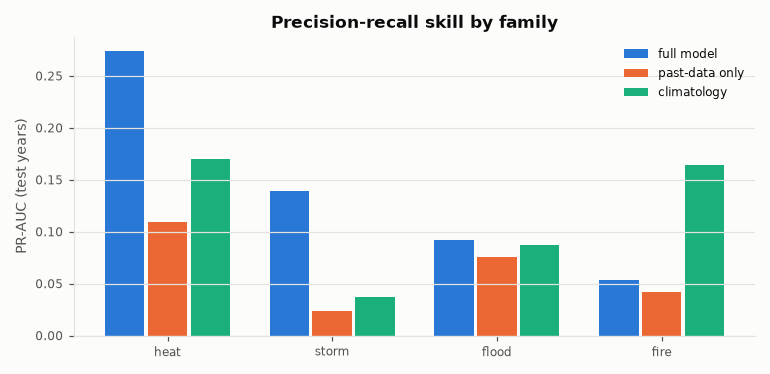

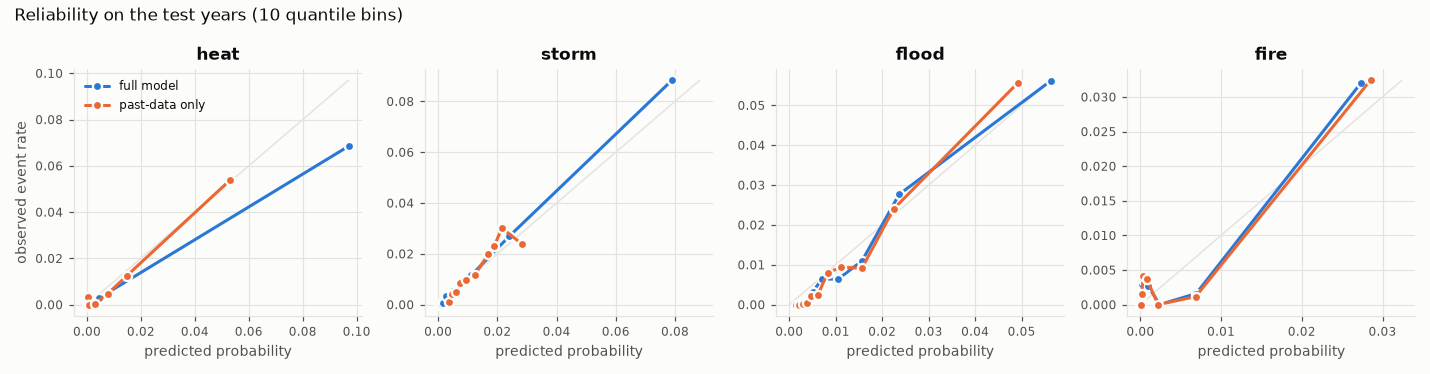

In [7]:
display(Image(filename=str(MD / "figures" / "pr_auc.png")))
display(Image(filename=str(MD / "figures" / "reliability.png")))

## 4. The 0–10 map

fallback points used: False


,R,score
0,0.000,0.0
1,0.013,1.5
2,0.015,2.0
3,0.034,4.0
4,0.107,7.5
5,0.334,10.0


removed (median R not increasing): [{'median_r': 0.014623275331170568, 'rule_max': 2.5, 'days': 898}, {'median_r': 0.011776644912901207, 'rule_max': 3.0, 'days': 10992}, {'median_r': 0.027296168432564754, 'rule_max': 5.0, 'days': 3286}, {'median_r': 0.02951078049921277, 'rule_max': 6.0, 'days': 2406}, {'median_r': 0.0635886900728501, 'rule_max': 9.0, 'days': 61}]


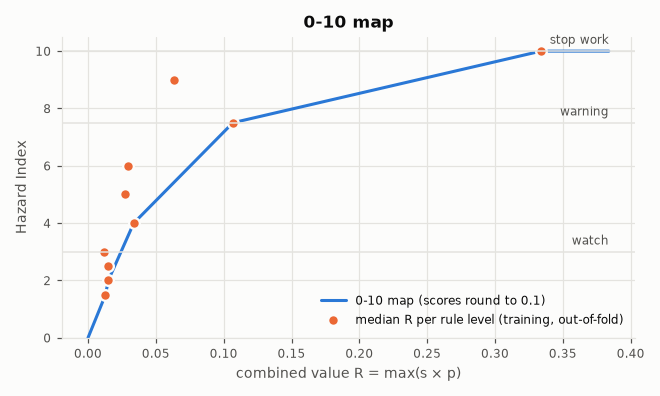

In [8]:
tm = json.loads((MD / "tier_map.json").read_text())
print("fallback points used:" , tm["fallback"])
display(pd.DataFrame(tm["points"], columns=["R", "score"]))
if tm["removed"]:
    print("removed (median R not increasing):", tm["removed"])
display(Image(filename=str(MD / "figures" / "tier_map.png")))

**Rejected alternative: quantile matching.** It maps `R` so that ML scores have the same distribution as the
historical rule maximum. Below, both maps are fitted on the same out-of-fold training days and applied to the test
years. Quantile matching can never show more total danger than the rules, and it inherits the steps of the rule scores.

,fitted map,quantile matching,rule maximum
>= 3,24.69%,37.18%,33.96%
>= 7.5,4.20%,2.08%,2.01%
>= 10,0.90%,0.16%,0.23%


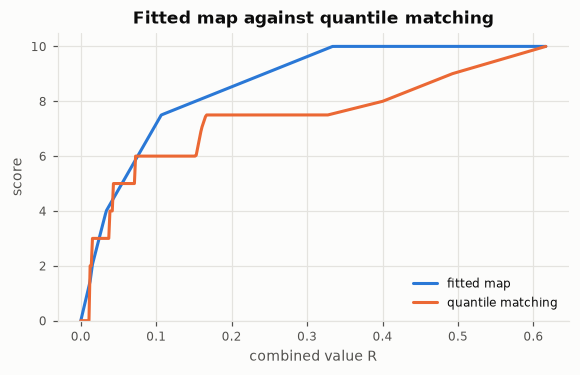

In [9]:
oof = preds[preds["split"] == "train_oof"]
test = preds[preds["split"] == "test"].copy()
q = np.linspace(0, 1, 1001)
r_q, rule_q = np.quantile(oof["R"], q), np.quantile(oof["rule_max"], q)
test["score_quantile_matched"] = np.interp(test["R"], r_q, rule_q)
share = lambda s, c: float((s >= c).mean())
cmp = pd.DataFrame({name: {f">= {c}": share(test[col], c) for c in (3, 7.5, 10)}
                    for name, col in (("fitted map", "score"), ("quantile matching", "score_quantile_matched"),
                                      ("rule maximum", "rule_max"))})
display(cmp.style.format("{:.2%}"))
grid = np.linspace(0, max(oof["R"].quantile(0.999), tm["points"][-1][0]), 400)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(grid, np.interp(grid, [p[0] for p in tm["points"]], [p[1] for p in tm["points"]]), color=plots.SERIES[0], label="fitted map")
ax.plot(grid, np.interp(grid, r_q, rule_q), color=plots.SERIES[1], label="quantile matching")
ax.set_xlabel("combined value R"); ax.set_ylabel("score"); ax.set_ylim(0, 10.5); ax.legend(loc="lower right")
ax.set_title("Fitted map against quantile matching")
plt.show()

## 5. Index tier against rule tier, and escalation (test years)

In [10]:
ix = metrics["index"]
print(f"ROC-AUC for any event: index {ix['roc_auc_any_event']:.3f}, rule maximum {ix['rule_max_roc_auc_any_event']:.3f}")
print(f"PR-AUC for any event:  index {ix['pr_auc_any_event']:.3f}, rule maximum {ix['rule_max_pr_auc_any_event']:.3f}"
      f"  (event rate {ix['any_event_rate']:.3f})")
order = ["none", "watch", "warning", "stop"]
days = pd.DataFrame(ix["tier_table"]["days"]).T.loc[order, order]
rate = pd.DataFrame(ix["tier_table"]["event_rate"]).T.loc[order, order]
days.index.name, days.columns.name = "index tier", "rule tier"
display(days)
display(rate.style.format("{:.1%}", na_rep="-"))
e = ix["escalation"]
print(f"Escalation (index > rule max + {e['points']:g}): {e['days']} days, event rate "
      f"{e['event_rate'] if e['event_rate'] is None else round(e['event_rate'], 3)} vs "
      f"{e['same_rule_tier_event_rate'] if e['same_rule_tier_event_rate'] is None else round(e['same_rule_tier_event_rate'], 3)}"
      " on other days at the same rule tier")
print("top driver share:", {k: round(v, 3) for k, v in ix["top_driver_share"].items()})

ROC-AUC for any event: index 0.832, rule maximum 0.733
PR-AUC for any event:  index 0.195, rule maximum 0.109  (event rate 0.035)


rule tier,none,watch,warning,stop
index tier,,,,
none,24699,8225,62,0
watch,3863,4790,309,11
warning,332,879,213,22
stop,31,101,195,68


,none,watch,warning,stop
none,0.9%,2.2%,8.1%,-
watch,5.5%,9.4%,8.4%,9.1%
warning,11.7%,23.1%,24.4%,18.2%
stop,9.7%,37.6%,39.5%,48.5%


Escalation (index > rule max + 2): 8156 days, event rate 0.086 vs 0.018 on other days at the same rule tier
top driver share: {'flood': 0.535, 'storm': 0.224, 'fire': 0.163, 'heat': 0.078}


## 6. Case study: West County Energy Center, August 2024 (the brief's scenario)

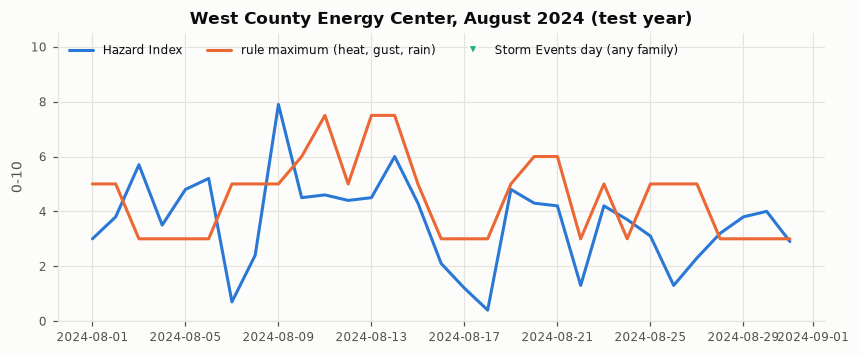

,date,score,top_driver,p_heat,p_storm,p_flood,p_fire,rule_max,wbgt_max,hi_max,gust_max,rain_24h,rain_prev7d,sm07_mean,y_heat,y_storm,y_flood
45126,2024-08-09,7.9,storm,0.005,0.170,0.035,2.639e-05,5.0,86.062,99.680,21.3,19.3,49.4,0.331,0,0,0
45131,2024-08-14,6.0,heat,0.075,0.032,0.010,3.206e-05,7.5,89.550,107.882,13.0,3.6,37.0,0.328,0,0,0
45120,2024-08-03,5.7,storm,0.002,0.083,0.029,5.611e-05,3.0,83.903,95.842,28.4,11.4,57.5,0.357,0,0,0
45123,2024-08-06,5.2,storm,0.004,0.071,0.016,1.968e-05,3.0,84.835,99.619,27.3,6.2,70.2,0.351,0,0,0
45122,2024-08-05,4.8,storm,0.002,0.060,0.027,2.670e-05,3.0,83.785,97.537,33.1,10.8,78.4,0.365,0,0,0
45136,2024-08-19,4.8,storm,0.004,0.061,0.023,3.104e-05,5.0,86.397,99.127,13.9,7.8,27.3,0.317,0,0,0
45128,2024-08-11,4.6,storm,0.008,0.056,0.012,2.092e-05,7.5,89.452,104.556,15.7,3.4,57.6,0.360,0,0,0
45127,2024-08-10,4.5,storm,0.017,0.053,0.020,2.001e-05,6.0,87.734,103.092,13.9,4.0,65.0,0.338,0,0,0


In [11]:
wc = preds[(preds["eia_plant_id"] == "56407") & (preds["date"].dt.strftime("%Y-%m") == "2024-08")].copy()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(wc["date"], wc["score"], color=plots.SERIES[0], label="Hazard Index")
ax.plot(wc["date"], wc["rule_max"], color=plots.SERIES[1], label="rule maximum (heat, gust, rain)")
ev = wc[wc["y_any"] == 1]
ax.plot(ev["date"], np.full(len(ev), 0.4), linestyle="none", marker="v", markersize=7, color=plots.SERIES[2],
        markeredgecolor=plots.SURFACE, markeredgewidth=1.5, label="Storm Events day (any family)")
ax.set_ylim(0, 10.5); ax.set_ylabel("0-10"); ax.legend(loc="upper left", ncols=3)
ax.set_title("West County Energy Center, August 2024 (test year)")
plt.show()
cols = ["date", "score", "top_driver", "p_heat", "p_storm", "p_flood", "p_fire", "rule_max", "wbgt_max", "hi_max",
        "gust_max", "rain_24h", "rain_prev7d", "sm07_mean", "y_heat", "y_storm", "y_flood"]
display(wc.sort_values("score", ascending=False)[cols].head(8))

In [12]:
replays = sorted((ART / "dryrun").glob("replay_*_56407.csv"))
for f in replays:
    print(f.name)
    display(pd.read_csv(f, dtype={"eia_plant_id": str}).T)

replay_20240809_56407.csv


,0,1
eia_plant_id,56407,56407
horizon,now,tomorrow
score,7.9,4.5
model_version,hazidx-0.1.0+2020-2022.c15a2e8c,hazidx-0.1.0+2020-2022.c15a2e8c
site_name,West County Energy Center,West County Energy Center
timezone,America/New_York,America/New_York
local_date,2024-08-09,2024-08-10
top_driver,storm,storm
r_raw,0.141,0.044
p_heat,0.005,0.017


replay_20240814_56407.csv


,0,1
eia_plant_id,56407,56407
horizon,now,tomorrow
score,6.0,4.3
model_version,hazidx-0.1.0+2020-2022.c15a2e8c,hazidx-0.1.0+2020-2022.c15a2e8c
site_name,West County Energy Center,West County Energy Center
timezone,America/New_York,America/New_York
local_date,2024-08-14,2024-08-15
top_driver,heat,storm
r_raw,0.075,0.04
p_heat,0.075,0.005


## 7. Live dry-run

In [13]:
runs = sorted((ART / "dryrun").glob("ml_scores_*.csv"))
live = pd.read_csv(runs[-1], dtype={"eia_plant_id": str})
print(runs[-1].name, len(live), "rows;", live["model_version"].iloc[0])
display(live.groupby("horizon")["score"].describe())
display(pd.crosstab(live["top_driver"], live["horizon"]))
print("rows with drift flags:", int(live["drift_flags"].notna().sum()), "| soil source:", live["soil_source"].value_counts().to_dict())
display(live.sort_values("risk_preview", ascending=False)[["site_name", "horizon", "local_date", "score", "top_driver",
        "rule_max_fc", "risk_preview", "forecast_hours", "drift_flags"]].head(10))

ml_scores_20261018T001527Z.csv 120 rows; hazidx-0.1.0+2020-2022.c15a2e8c


,count,mean,std,min,25%,50%,75%,max
horizon,,,,,,,,
now,60.0,1.082,1.094,0.1,0.275,0.60,1.400,4.1
tomorrow,60.0,0.813,0.944,0.1,0.200,0.35,1.125,4.7


horizon,now,tomorrow
top_driver,,
fire,29,31
flood,19,26
storm,12,3


rows with drift flags: 15 | soil source: {'ecmwf_ifs': 120}


,site_name,horizon,local_date,score,top_driver,rule_max_fc,risk_preview,forecast_hours,drift_flags
84,Victor J Daniel Jr,now,2026-10-17,0.1,flood,6.0,6.0,4,NaN
22,Turkey Point,now,2026-10-17,0.6,storm,5.0,5.0,3,td_max>p99.5
23,Turkey Point,tomorrow,2026-10-18,4.7,storm,3.0,4.7,24,NaN
48,Roxboro,now,2026-10-17,4.1,storm,3.0,4.1,3,NaN
14,Crystal River,now,2026-10-17,4.1,storm,3.0,4.1,3,NaN
95,Calvert Cliffs Nuclear Power Plant,tomorrow,2026-10-18,0.2,flood,4.0,4.0,24,NaN
94,Calvert Cliffs Nuclear Power Plant,now,2026-10-17,3.7,storm,4.0,4.0,3,rain_hr_max>p99.5;wind_max>p99.5
90,Ravenswood,now,2026-10-17,0.6,storm,4.0,4.0,3,NaN
79,Jim Bridger,tomorrow,2026-10-18,3.0,fire,0.0,3.0,24,NaN
32,South Texas Project,now,2026-10-17,1.4,fire,3.0,3.0,4,NaN


## 8. Findings

_Findings are written after the first trained model._